Para el proyecto final usaré la metodología de Machine Learning, para este usaré el dataset de Iris que se encuentra en la página https://www.kaggle.com/uciml/iris.

# Información del Dataset.

La data contiene 3 clases de 50 instancias cada uno, donde cada clase se refiere a un tipo de las plantas de Iris.
una clase es linealmente separable de las otras 2, estas últimas no son linealmente separables entre sí.

Atributos de información:
    1. Longitud del sépalo en cm.
    2. Ancho del sépalo en cm.
    3. Longitud del petalo en cm.
    4. Ancho del petalo en cm.
    5. Tipos de clases: Iris setosa, Iris Versicolor e Iris Virginica.

## Importar módulos

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.colors as colors
from sklearn import datasets, linear_model, metrics
from pandas.plotting import andrews_curves, scatter_matrix, parallel_coordinates, lag_plot,autocorrelation_plot, bootstrap_plot,radviz
import pandas as pd
import numpy as np
import os
import seaborn as sns

## Carga del dataset

In [2]:
df = pd.read_csv("Iris.csv")
df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


# ---------------------------------------------------------------------------------------------------------------

## Mostrar las columnas que hay en el Dataset

In [3]:
df.keys()

Index(['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm',
       'Species'],
      dtype='object')

# ---------------------------------------------------------------------------------------------------------------

## Eliminar la columna Id ya que es innecesaria para el procesamiento de datos

In [4]:
df = df.drop(columns = ["Id"])
df.head()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


# ---------------------------------------------------------------------------------------------------------------

## Arrojar información sobre el Dataset

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   SepalLengthCm  150 non-null    float64
 1   SepalWidthCm   150 non-null    float64
 2   PetalLengthCm  150 non-null    float64
 3   PetalWidthCm   150 non-null    float64
 4   Species        150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


# ---------------------------------------------------------------------------------------------------------------

## Contar los datos de acuerdo a las 3 clases de la flor Iris

In [6]:
df["Species"].value_counts()

Iris-virginica     50
Iris-setosa        50
Iris-versicolor    50
Name: Species, dtype: int64

# ---------------------------------------------------------------------------------------------------------------

## Preprocesamiento del dataset

In [7]:
df.isnull().sum()

SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64

# ---------------------------------------------------------------------------------------------------------------

## Análisis exploratorio de datos

# ---------------------------------------------------------------------------------------------------------------

### Gráficas de histogramas de acuerdo al longitud y ancho del Pétalo y el Sépalo

- Longitud del sépalo

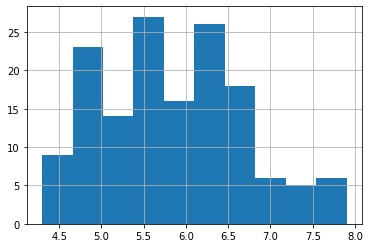

In [8]:
df["SepalLengthCm"].hist()

- Ancho del sépalo

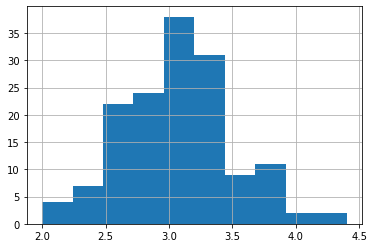

In [9]:
df["SepalWidthCm"].hist()

- Longitud del pétalo

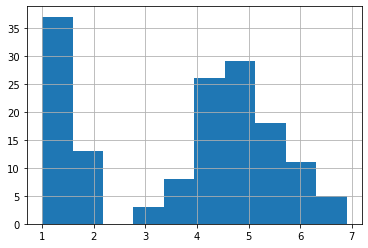

In [10]:
df["PetalLengthCm"].hist()

- Ancho del pétalo

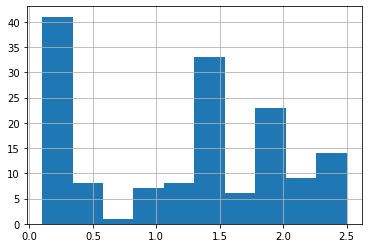

In [11]:
df["PetalWidthCm"].hist()

# ---------------------------------------------------------------------------------------------------------------

# Gráficas de Scatter

## Creación de variables a nivel global

In [12]:
colors = ["red", "orange", "blue"]
species = ["Iris-virginica", "Iris-versicolor", "Iris-setosa"]

## Uso de variables creadas para hacer las gráficas.

- Gráfica de Scatter entre la Longitud del sépalo y el Ancho del sépalo

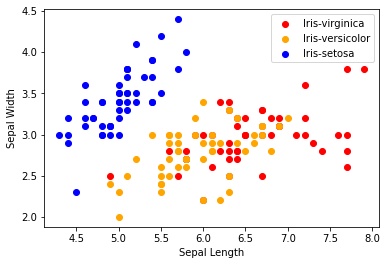

In [13]:
for i in range(3):
    x = df[df["Species"] == species[i]]
    plt.scatter(x["SepalLengthCm"], x["SepalWidthCm"], c = colors[i], label=species[i])
plt.xlabel("Sepal Length")
plt.ylabel("Sepal Width")
plt.legend()

- Gráfica de Scatter entre la Longitud del Pétalo y el Ancho del Pétalo

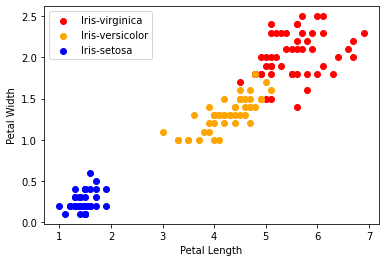

In [14]:
for i in range(3):
    x = df[df["Species"] == species[i]]
    plt.scatter(x["PetalLengthCm"], x["PetalWidthCm"], c = colors[i], label=species[i])
plt.xlabel("Petal Length")
plt.ylabel("Petal Width")
plt.legend()

- Gráfica de Scatter entre la Longitud del Sépalo y la Longitud del Pétalo

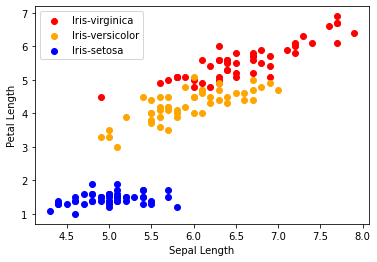

In [15]:
for i in range(3):
    x = df[df["Species"] == species[i]]
    plt.scatter(x["SepalLengthCm"], x["PetalLengthCm"], c = colors[i], label=species[i])
plt.xlabel("Sepal Length")
plt.ylabel("Petal Length")
plt.legend()

- Gráfica de Scatter entre el Ancho del Sépalo y el Ancho del Pétalo

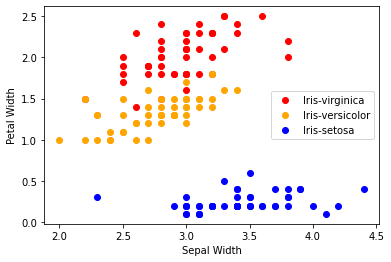

In [16]:
for i in range(3):
    x = df[df["Species"] == species[i]]
    plt.scatter(x["SepalWidthCm"], x["PetalWidthCm"], c = colors[i], label=species[i])
plt.xlabel("Sepal Width")
plt.ylabel("Petal Width")
plt.legend()

# ---------------------------------------------------------------------------------------------------------------

## Matriz de correlación

La matriz de correlación es una tabla que muestra la correlación entre coeficientes entre variables. Cada celda en la tabla muestra la correlación entre dos variables. El valor está en el rango de -1 a 1. Si las dos variables tienen una correlación grande, nosotros podemos descuidar una variable de esas dos.

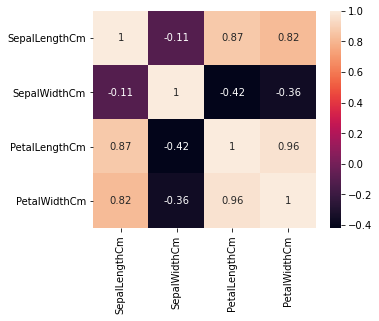

In [17]:
corr = df.corr()
fig, ax = plt.subplots(figsize=(5,4))
sns.heatmap(corr, annot=True, ax=ax)

# ---------------------------------------------------------------------------------------------------------------

## Label Encoder

En Machine Learning, normalmente tratamos con conjuntos de datos que contienen varias etiquetas en una o más de una columna. Estas etiquetas pueden tener la forma de palabras o números. La codificación de etiquetas se refiere a convertir las etiquetas en forma numérica para convertirlas en una forma legible por máquina

- Cambiar los nombres de las 3 clases de Iris a números del 0 al 2

In [18]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
df['Species'] = le.fit_transform(df['Species'])
df.head()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


# ---------------------------------------------------------------------------------------------------------------

## Entrenamiento del modelo

In [19]:
from sklearn.model_selection import train_test_split
# train - 70
# test - 30
X = df.drop(columns=['Species'])
Y = df['Species']
x_train, x_test, y_train, y_test = train_test_split(X, Y, test_size=0.30)

# ---------------------------------------------------------------------------------------------------------------

## Regresión logistica

In [20]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression()

In [21]:
# model training
model.fit(x_train, y_train)

LogisticRegression()

# ---------------------------------------------------------------------------------------------------------------

## Modelo de vecinos más cercanos

In [22]:
from sklearn.neighbors import KNeighborsClassifier
model = KNeighborsClassifier()

In [23]:
model.fit(x_train, y_train)

KNeighborsClassifier()

# ---------------------------------------------------------------------------------------------------------------

## Imprimir la métrica para obtener el rendimiento de la data

In [24]:
print("Accuracy: ",model.score(x_test, y_test) * 100)

Accuracy:  100.0


# ---------------------------------------------------------------------------------------------------------------

## Modelo de regresión líneal simple

In [25]:
msk = np.random.rand(len(df)) < 0.8 # 80% of entire data for training and 20% fot testing
train = df[msk]
test = df[~msk]

In [26]:
from sklearn import linear_model
regr = linear_model.LinearRegression()
train_x = np.asanyarray(train[['SepalLengthCm']])
train_y = np.asanyarray(train[['PetalLengthCm']])
regr.fit(train_x, train_y)

# The coefficients
print ('Coefficients: ', regr.coef_)
print ('Intercept: ', regr.intercept_)

Coefficients:  [[1.86387099]]
Intercept:  [-7.12708103]


### Trazar las salidas del entrenamiento de datos

Text(0, 0.5, 'Petal Length Cm')

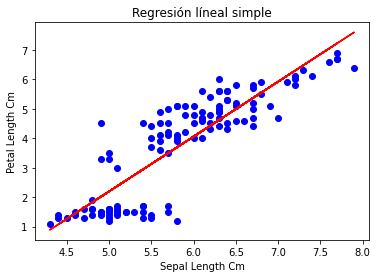

In [27]:
plt.scatter(train.SepalLengthCm, train.PetalLengthCm,  color='blue')
plt.plot(train_x, regr.coef_[0][0]*train_x + regr.intercept_[0], '-r')
plt.title('Regresión líneal simple') 
plt.xlabel("Sepal Length Cm")
plt.ylabel("Petal Length Cm")

# ---------------------------------------------------------------------------------------------------------------

### Matriz de confusión

In [28]:
lr = LogisticRegression(solver='lbfgs', max_iter=200)
lr.fit(x_train, y_train)
y_pre = lr.predict(x_test)

In [29]:
cnf_matrix = metrics.confusion_matrix(y_test,y_pre)

Text(0.5, 257.44, 'Prediction Label')

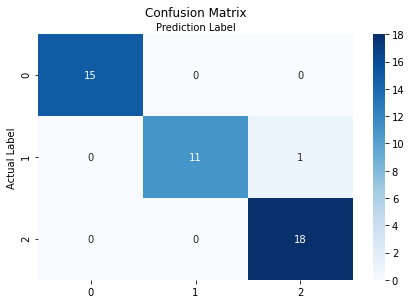

In [30]:
class_names = [0,1]
fig, ax = plt.subplots()
ticks_marks = np.arange(len(class_names))
plt.xticks(ticks_marks, class_names)
plt.yticks(ticks_marks, class_names)
sns.heatmap(pd.DataFrame(cnf_matrix), annot=True, cmap='Blues', fmt='g') # fmt='g' is for the annot shows in normal numbers 
ax.xaxis.set_label_position('top')
ax.autoscale(enable=True) # To fix scale 
plt.tight_layout()
plt.title('Confusion Matrix', y = 2.1)
plt.ylabel('Actual Label')
plt.xlabel('Prediction Label')

# ---------------------------------------------------------------------------------------------------------------

## Diagrama de barras con toda la información de la Data 

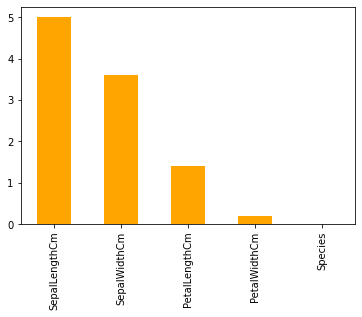

In [31]:
plt.figure()
df.iloc[4].plot(kind='bar', color="orange");

# ---------------------------------------------------------------------------------------------------------------

## Gráfica del dataset de tipo caja

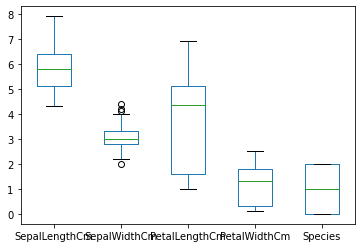

In [32]:
df.plot(kind="box", sharex=False, sharey=False)

## Gráfica del dataset de tipo caja por clase.

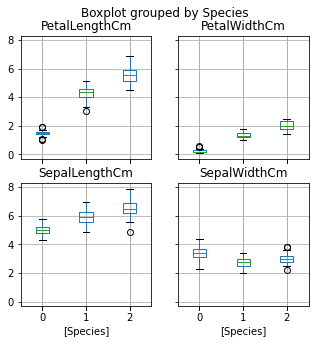

In [54]:
df.boxplot(by="Species", figsize=(5,5));

# ---------------------------------------------------------------------------------------------------------------

## Gráfica del área de todo el Dataset

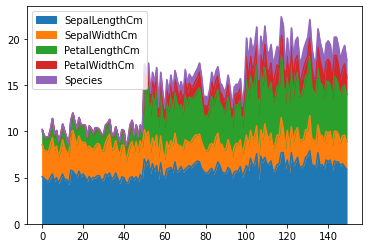

In [34]:
df.plot(kind="area", sharex=False, sharey=False)

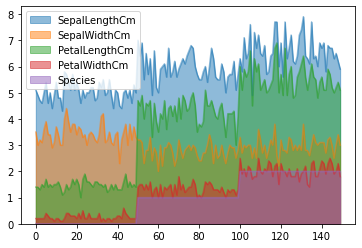

In [35]:
df.plot.area(stacked=False);

# ---------------------------------------------------------------------------------------------------------------

## Gráfico de densidad

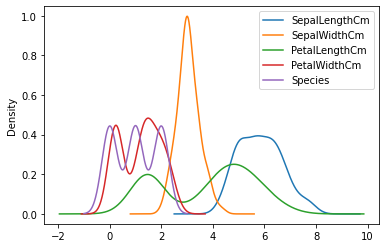

In [36]:
df.plot(kind="kde", sharex=False, sharey=False)

# ---------------------------------------------------------------------------------------------------------------

# Gráfica de histogramas

## Por cada columna

<Figure size 432x288 with 0 Axes>

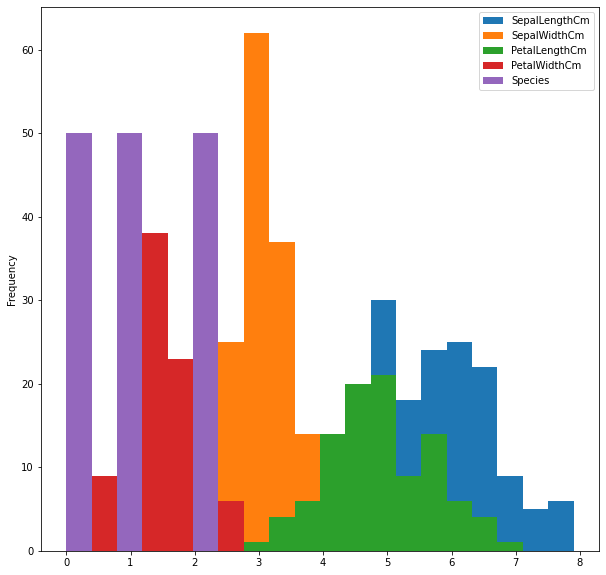

In [37]:
plt.figure();
df.plot.hist(bins=20, figsize=(10,10))

## Por cada columna de forma horizontal y acumulativa

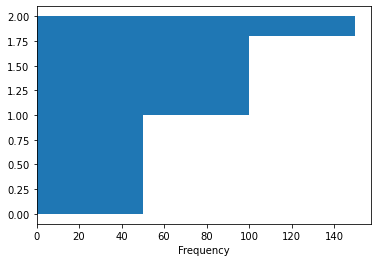

In [38]:
plt.figure();
df['Species'].plot.hist(orientation='horizontal', cumulative=True)

## Todas las columnas de separada

<Figure size 432x288 with 0 Axes>

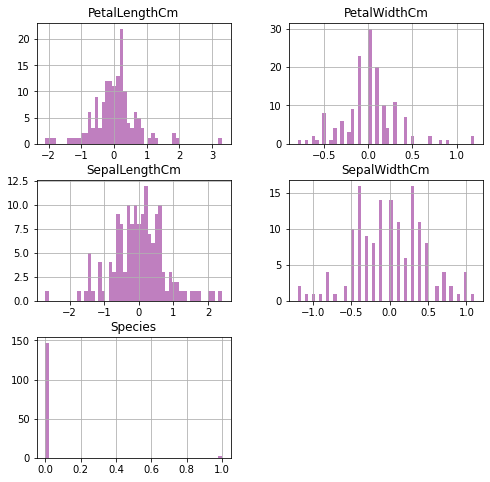

In [39]:
plt.figure()
df.diff().hist(color='purple', alpha=0.5, bins=50, figsize=(8,8));

# ---------------------------------------------------------------------------------------------------------------

## Gráfica de contenedor hexagonal

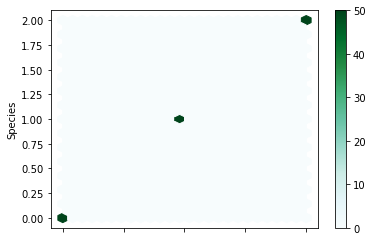

In [40]:
df.plot.hexbin(x='Species', y='Species', gridsize=25)

# ---------------------------------------------------------------------------------------------------------------

## Gráfico de torta o circular

array([<matplotlib.axes._subplots.AxesSubplot object at 0x000001FAC2CDB1C0>],
      dtype=object)

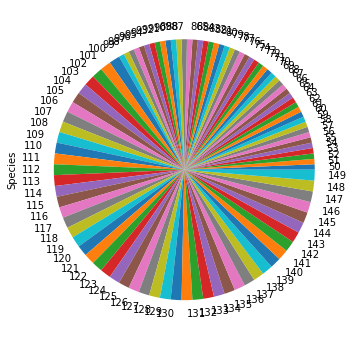

In [41]:
df['Species'].plot.pie(figsize=(6, 6), subplots=True)

# ---------------------------------------------------------------------------------------------------------------

## Gráfico de matriz de dispersión

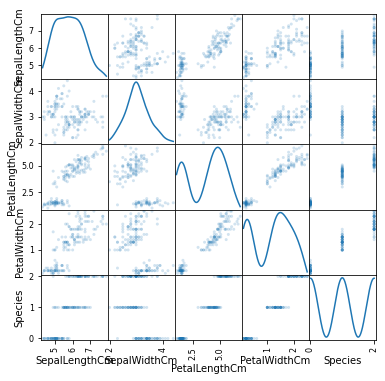

In [42]:
scatter_matrix(df, alpha=0.2, figsize=(6, 6), diagonal='kde');

# ---------------------------------------------------------------------------------------------------------------

## Curvas de Andrews

Al colorear estas curvas de manera diferente para cada clase, es posible visualizar la agrupación de datos. Las curvas que pertenecen a muestras de la misma clase suelen estar más juntas y formar estructuras más grandes.

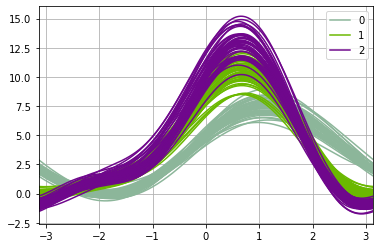

In [43]:
plt.figure()
andrews_curves(df, 'Species')

# ---------------------------------------------------------------------------------------------------------------

## Coordenadas paralelas

- Permiten ver grupos de datos y estimar otras estadísticas visualmente.
- Los puntos se representan como segmentos de línea conectados

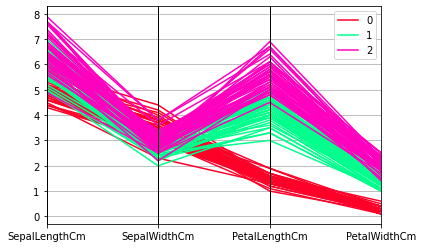

In [44]:
plt.figure()
parallel_coordinates(df, 'Species', colormap='gist_rainbow')

# ---------------------------------------------------------------------------------------------------------------

## Gráfico de retraso

Se utilizan para verificar si un conjunto de datos o una serie de tiempo es aleatorio

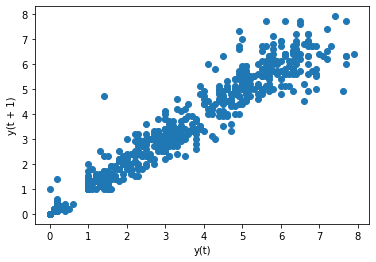

In [45]:
plt.figure()
lag_plot(df)

La estructura anterior como no es aleatoria(Formar una figura) implica que los datos subyacentes no son aleatorio.

# ---------------------------------------------------------------------------------------------------------------

## Gráfica de RadViz

- Cada punto representa un atributo único

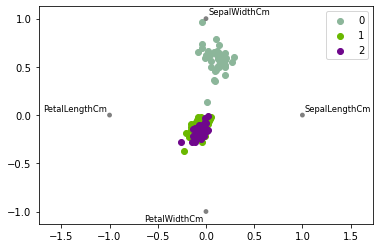

In [46]:
plt.figure()
radviz(df, 'Species')

Donde estan los puntos es donde se asientan nuestras muestras

# ---------------------------------------------------------------------------------------------------------------

## Diseño de las subparcelas

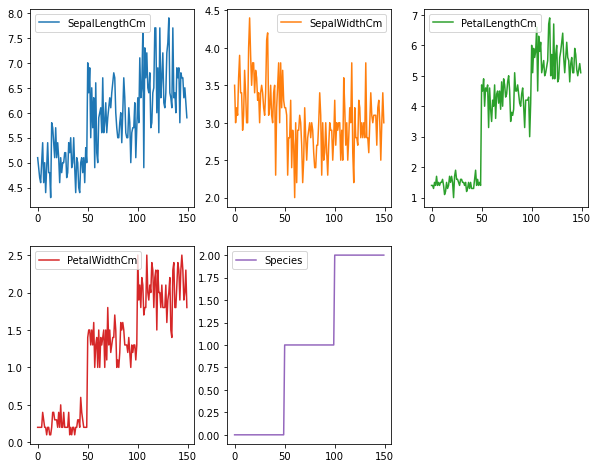

In [47]:
df.plot(subplots=True, layout=(2, 3), figsize=(10, 8), sharex=False);

# ---------------------------------------------------------------------------------------------------------------

## Grafico de la longitud del petalo con para cada especie o clase.

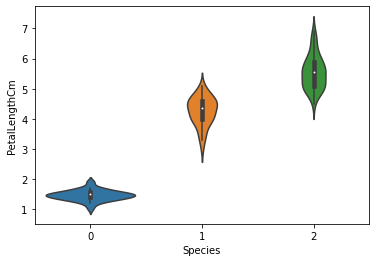

In [48]:
sns.violinplot(data=df, x="Species", y="PetalLengthCm")

### Matriz de diagrama de disperciòn

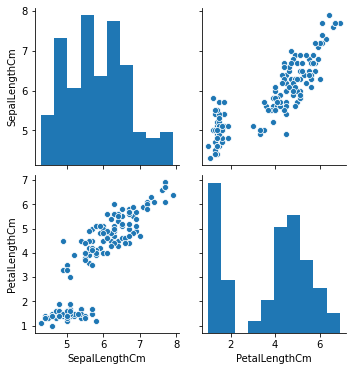

In [57]:
sns.pairplot(df[['SepalLengthCm', 'PetalLengthCm']])

### Uso de la gráfica de par de mar para ver la relación bivariada entre cada par de caracteristícas 

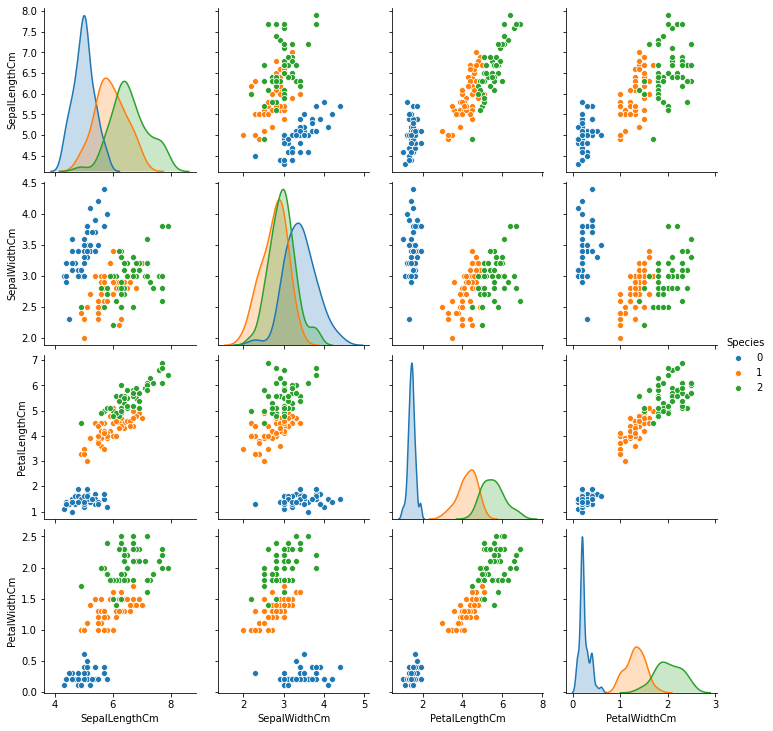

In [50]:
sns.pairplot(df, hue="Species")

### Actualizando los elementos diagonales en un diagrama de par para mostrar un Kde

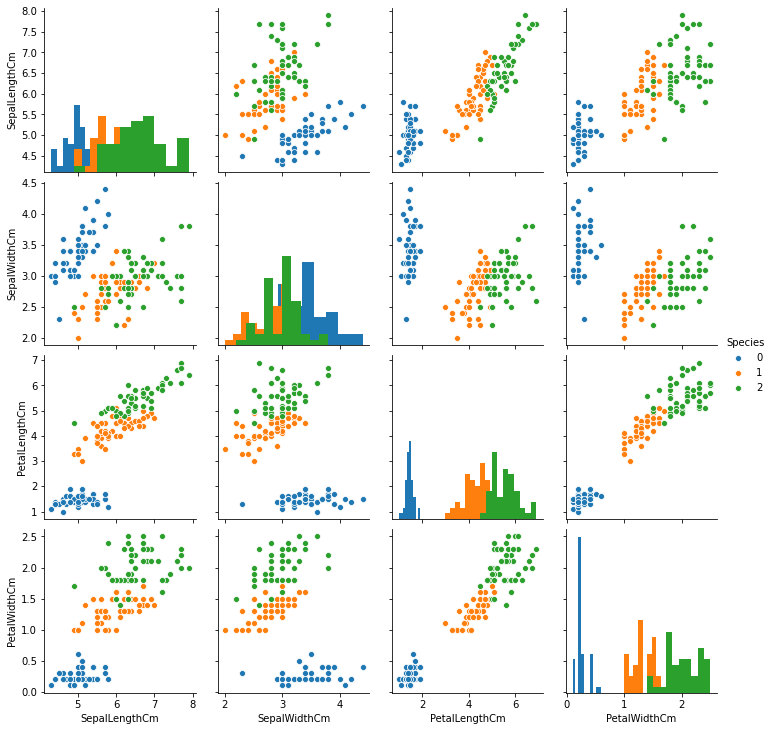

In [51]:
sns.pairplot(df, hue="Species", diag_kind="hist")